# Auditoría de los datos de Oslo — Proyecto 2
## 1. Objetivo y descripción de las fuentes
Evaluar calidad, cobertura y utilidad de los datos antes de construir el modelo espacial y temporal. Se utilizan **exclusivamente** los dos archivos existentes en `data/project2/raw/oslo/`.

- `floral_density_data_dryad_version.txt`: taxones vegetales, número de flores, trap, fecha, dimensiones del transecto y comentarios.
- `floral_visitation_data_dryad_version.txt`: taxones de polinizadores, individuos volando y posados, planta asociada, fecha, horarios, observadores y condiciones climáticas.

Una fila no equivale necesariamente a un sitio, una sesión independiente ni una visita efectiva. Estos archivos no incluyen un protocolo que resuelva todas las definiciones de muestreo. No se descargan datos ni se implementa una simulación.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import hashlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_colwidth", 95)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}")

Python 3.10.11 | pandas 2.3.3 | numpy 2.2.6 | matplotlib 3.10.9


## 2. Carga robusta y reproducible
Se busca la raíz desde el directorio de ejecución hacia sus padres: funciona desde la raíz o desde `notebooks/project2`. Los archivos están separados por tabulaciones. Se intenta UTF-8 y después Windows-1252, sin reemplazar silenciosamente caracteres. `NA`, `N/A` y campos vacíos se consideran ausencias. Las huellas SHA-256 identifican las entradas. No se eliminan filas ni se imputan mediciones.

In [2]:
REL = Path("data/project2/raw/oslo")
FILES = {"flora": "floral_density_data_dryad_version.txt",
         "visitas": "floral_visitation_data_dryad_version.txt"}
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if all((p / REL / name).is_file() for name in FILES.values())), None)
if ROOT is None:
    raise FileNotFoundError("Ejecute desde el repositorio o un subdirectorio; faltan los archivos de Oslo.")

def load_table(path):
    for encoding in ("utf-8-sig", "cp1252"):
        try:
            return pd.read_csv(path, sep="\t", encoding=encoding,
                               na_values=["NA", "N/A", ""], on_bad_lines="error"), encoding
        except UnicodeDecodeError:
            continue
    raise UnicodeError(f"No se pudo interpretar {path.name}")

raw, provenance = {}, []
for label, name in FILES.items():
    path = ROOT / REL / name
    raw[label], encoding = load_table(path)
    provenance.append({"dataset": label, "ruta relativa": str(REL / name),
                       "codificación": encoding,
                       "SHA-256": hashlib.sha256(path.read_bytes()).hexdigest()})
display(pd.DataFrame(provenance))

,dataset,ruta relativa,codificación,SHA-256
0,flora,data\project2\raw\oslo\floral_density_data_dryad_version.txt,utf-8-sig,7750a3be81229e57a8052136e2a46f1599c5e1c33d654e9e050b82979039bd53
1,visitas,data\project2\raw\oslo\floral_visitation_data_dryad_version.txt,cp1252,71813660a8ade147a46c4dbc42803be5f127b9e8611f300eac1374dd7da15bb1


## 3. Dimensiones, columnas, tipos y primeras filas

In [3]:
for label, df in raw.items():
    print(f"\n{label}: {df.shape[0]:,} filas × {df.shape[1]} columnas")
    display(pd.DataFrame({"columna": df.columns, "tipo original": df.dtypes.astype(str).values}))
    display(df.head())


flora: 593 filas × 7 columnas


,columna,tipo original
0,trap_number,int64
1,inventory_date,object
2,plant_species_latin_name,object
3,flower_number,float64
4,transect_width_cm,int64
5,transect_length_m,int64
6,comments,object


,trap_number,inventory_date,plant_species_latin_name,flower_number,transect_width_cm,transect_length_m,comments
0,101,19.jul,Galeopsis,1.0,40,20,NaN
1,101,19.jul,Alchemilla,1.0,40,20,NaN
2,101,19.jul,Vicia sp.,25.0,40,20,NaN
3,101,19.jul,Chamerion angustifolium,1.0,40,20,NaN
4,101,19.jul,Stellaria graminea,6.0,40,20,NaN



visitas: 1,297 filas × 16 columnas


,columna,tipo original
0,trap_number,int64
1,inventory_date,object
2,observer1,object
3,observer2,object
4,observation_start,object
5,observation_end,object
6,temperature_C,float64
7,sky_cover,float64
8,wind,object
9,rain,object


,trap_number,inventory_date,observer1,observer2,observation_start,observation_end,temperature_C,sky_cover,wind,rain,additional_comments,pollinator_species_latin,sex,individuals_flying,individuals_sitting,plant_species_latin
0,101,29.07.2017,SD,NaN,11:32,11:42,15.0,80.0,NaN,some rain,NaN,Apis mellifera,NaN,1,0,NaN
1,101,19.07.2017,AK,NaN,10:32,10:49,16.5,80.0,windy,NaN,NaN,Apis mellifera,NaN,0,5,Bunias orientalis
2,101,21.07.2017,AK,NaN,11:10,11:22,16.0,100.0,no wind,NaN,NaN,Apis mellifera,NaN,1,0,NaN
3,101,21.07.2017,AK,NaN,11:10,11:22,16.0,100.0,no wind,NaN,NaN,Apis mellifera,NaN,0,1,Rubus idaeus
4,101,29.07.2017,SD,NaN,11:32,11:42,15.0,80.0,NaN,some rain,NaN,Bombus hypnorum,NaN,0,2,Chamerion angustifolium


## 4. Nulos, duplicados e inconsistencias
Se examinan primero los datos originales. Los duplicados exactos son **candidatos a revisión**, no errores confirmados: se conservan en los totales principales. Una tabla posterior muestra sensibilidad al excluirlos.

La copia de trabajo recorta espacios y convierte columnas numéricas conocidas, reportando errores. No fusiona taxones ni interpreta un dato climático ausente como «sin viento» o «sin lluvia». Si falta una columna esperada, se informa y se omite el análisis que depende de ella.

In [4]:
EXPECTED = {
    "flora": ["trap_number", "inventory_date", "plant_species_latin_name", "flower_number",
              "transect_width_cm", "transect_length_m", "comments"],
    "visitas": ["trap_number", "inventory_date", "observation_start", "observation_end",
                "pollinator_species_latin", "plant_species_latin", "individuals_flying",
                "individuals_sitting", "temperature_C", "sky_cover", "wind", "rain"]}
NUMERIC = ["flower_number", "transect_width_cm", "transect_length_m",
           "individuals_flying", "individuals_sitting", "temperature_C", "sky_cover"]
data = {}
for label, original in raw.items():
    print(f"\n{label} — columnas esperadas ausentes: {sorted(set(EXPECTED[label]) - set(original.columns)) or 'ninguna'}")
    display(pd.DataFrame({"nulos": original.isna().sum(),
                          "% nulos": original.isna().mean().mul(100).round(2)}))
    print("Duplicados exactos adicionales:", int(original.duplicated().sum()))
    display(original.loc[original.duplicated(keep=False)].head(12))
    df = original.copy(deep=True)
    for col in df.select_dtypes(include=["object", "string"]):
        clean = df[col].astype("string").str.strip().replace("", pd.NA)
        changed = (df[col].notna() & df[col].astype("string").ne(clean)).fillna(False).sum()
        if changed:
            print(f"{col}: {changed} registros con espacios exteriores corregidos")
        df[col] = clean
    for col in [x for x in NUMERIC if x in df]:
        numeric = pd.to_numeric(df[col], errors="coerce")
        invalid = df[col].notna() & numeric.isna()
        if invalid.any():
            print(f"{col}: valores no numéricos:", df.loc[invalid, col].tolist())
        df[col] = numeric
    print("Duplicados adicionales después de recortar espacios:", int(df.duplicated().sum()))
    data[label] = df
flora, visitas = data["flora"], data["visitas"]

def available(df, cols, section):
    missing = sorted(set(cols) - set(df.columns))
    if missing:
        print(f"{section}: no disponible; faltan {missing}")
    return not missing


flora — columnas esperadas ausentes: ninguna


,nulos,% nulos
trap_number,0,0.00
inventory_date,0,0.00
plant_species_latin_name,1,0.17
flower_number,1,0.17
transect_width_cm,0,0.00
transect_length_m,0,0.00
comments,503,84.82


Duplicados exactos adicionales: 4


,trap_number,inventory_date,plant_species_latin_name,flower_number,transect_width_cm,transect_length_m,comments
73,117,25.jul,Crepis sp.,13.0,40,20,NaN
74,117,25.jul,Crepis sp.,13.0,40,20,NaN
348,170,26.jul,Rubus idaeus,0.0,40,20,not in bloom
349,170,26.jul,Rubus idaeus,0.0,40,20,not in bloom
377,172,26.jul,Trifolium sp.,4.0,40,20,NaN
389,172,26.jul,Persicaria sp.,1.0,40,20,NaN
390,172,26.jul,Persicaria sp.,1.0,40,20,NaN
397,172,26.jul,Trifolium sp.,4.0,40,20,NaN


Duplicados adicionales después de recortar espacios: 4

visitas — columnas esperadas ausentes: ninguna


,nulos,% nulos
trap_number,0,0.00
inventory_date,1,0.08
observer1,0,0.00
observer2,967,74.56
observation_start,1,0.08
observation_end,92,7.09
temperature_C,26,2.00
sky_cover,20,1.54
wind,1096,84.50
rain,1208,93.14


Duplicados exactos adicionales: 6


,trap_number,inventory_date,observer1,observer2,observation_start,observation_end,temperature_C,sky_cover,wind,rain,additional_comments,pollinator_species_latin,sex,individuals_flying,individuals_sitting,plant_species_latin
202,119,08.08.2017,SH,SE,11:28,11:48,17.0,20.0,no wind,NaN,NaN,Bombus terrestris,NaN,0,1,Succisa pratensis
203,119,08.08.2017,SH,SE,11:28,11:48,17.0,20.0,no wind,NaN,NaN,Bombus terrestris,NaN,0,1,Succisa pratensis
259,125,22.07.2017,AK,NaN,15:51,16:03,22.0,10.0,NaN,NaN,NaN,Apis mellifera,NaN,0,1,Trifolium pratense
260,125,22.07.2017,AK,NaN,15:51,16:03,22.0,10.0,NaN,NaN,NaN,Apis mellifera,NaN,0,1,Trifolium pratense
787,171,28.07.2017,SE,NaN,17:22,17:48,20.0,50.0,NaN,NaN,NaN,Apis mellifera,NaN,0,1,Centaurea jacea
788,171,28.07.2017,SE,NaN,17:22,17:48,20.0,50.0,NaN,NaN,NaN,Apis mellifera,NaN,0,1,Centaurea jacea
1080,188,01.08.2017,SE,IK,11:36,11:50,20.0,30.0,NaN,NaN,NaN,Apis mellifera,NaN,0,1,Inula salicina
1081,188,01.08.2017,SE,IK,11:36,11:50,20.0,30.0,NaN,NaN,NaN,Apis mellifera,NaN,0,1,Inula salicina
1162,197,04.08.2017,SH,NaN,12:49,13:00,19.0,30.0,NaN,NaN,NaN,Apis mellifera,NaN,0,1,Trifolium hybridum
1163,197,04.08.2017,SH,NaN,12:49,13:00,19.0,30.0,NaN,NaN,NaN,Apis mellifera,NaN,0,1,Trifolium hybridum


wind: 4 registros con espacios exteriores corregidos
additional_comments: 2 registros con espacios exteriores corregidos
Duplicados adicionales después de recortar espacios: 6


In [5]:
issues = []
for label, df in data.items():
    for col in [x for x in NUMERIC if x in df]:
        s = df[col]
        issues.append({"dataset": label, "variable": col, "negativos": int(s.lt(0).sum()),
                       "ceros": int(s.eq(0).sum()), "mínimo": s.min(), "máximo": s.max(),
                       "no finitos no nulos": int((s.notna() & ~np.isfinite(s)).sum())})
        if col in ["flower_number", "individuals_flying", "individuals_sitting"]:
            print(label, col, "conteos fraccionarios:", int((s.notna() & s.mod(1).ne(0)).sum()))
    for col in [x for x in df if "species" in x]:
        values = df[col].dropna().drop_duplicates()
        variants = values[values.str.casefold().duplicated(keep=False)]
        if not variants.empty:
            print(f"{label}/{col}: variantes de mayúsculas (no fusionadas):", variants.tolist())
display(pd.DataFrame(issues))
if "sky_cover" in visitas:
    print("sky_cover fuera de 0–100 (unidad por confirmar):",
          int((visitas.sky_cover.notna() & ~visitas.sky_cover.between(0, 100)).sum()))
for label, df in data.items():
    for col in [x for x in ["comments", "additional_comments"] if x in df]:
        print(f"\n{label}/{col}: notas para revisar antes de modelar")
        display(df[col].value_counts(dropna=False).rename("registros").to_frame())

flora flower_number conteos fraccionarios: 14
visitas individuals_flying conteos fraccionarios: 0
visitas individuals_sitting conteos fraccionarios: 0
visitas/pollinator_species_latin: variantes de mayúsculas (no fusionadas): ['Bombus sp.', 'bombus sp.']


,dataset,variable,negativos,ceros,mínimo,máximo,no finitos no nulos
0,flora,flower_number,0,29,0.0,420.0,0
1,flora,transect_width_cm,0,0,20.0,40.0,0
2,flora,transect_length_m,0,0,10.0,20.0,0
3,visitas,individuals_flying,0,1121,0.0,14.0,0
4,visitas,individuals_sitting,0,193,0.0,55.0,0
5,visitas,temperature_C,0,0,12.5,27.0,0
6,visitas,sky_cover,0,20,0.0,100.0,0


sky_cover fuera de 0–100 (unidad por confirmar): 0

flora/comments: notas para revisar antes de modelar


,registros
comments,
<NA>,503
not in bloom,21
Urban garden,14
"Estimated transect length, not measured",11
"Two 10m transects surveyed, each 40cm in width",9
Urban agricultural field,7
Ten percent of transect is bare sand,6
"Short transect, not possible to record at full length",5
Roadside,4



visitas/additional_comments: notas para revisar antes de modelar


,registros
additional_comments,
<NA>,1140
collected,32
individual flew away before it could be identified to species,21
"6 beehives c. 30m away, many Apis mellifera in the area",18
"First two transects are 15m long, third transect is 30m long",17
no pollinators observed,14
mowed,11
"very wet, few pollinators flying, most are sitting",7
60m transect (30m on either side of the trap),5


## 5. Fechas, horarios y rango temporal
Las fechas completas se convierten con formatos explícitos. Las fechas florales como `19.jul` **no contienen año**: se extraen mes y día, dejando la fecha completa como `NaT`. No se asigna 2017 por proximidad al otro archivo. Se distinguen fechas completas, parciales, ausentes y no interpretables. El rango floral con año describe solo las filas que sí lo incluyen.

Las horas se convierten por separado. No se usan duraciones ausentes, no interpretables o no positivas para construir tasas. Horarios repetidos entre taxones pueden pertenecer a una misma sesión.

In [6]:
def parse_inventory(series):
    s = series.astype("string").str.strip().str.lower()
    complete = pd.to_datetime(s, format="%d.%m.%Y", errors="coerce")
    tokens = s.str.extract(r"^(\d{1,2})\.(jul|aug)(?:\.(\d{2}|\d{4}))?$")
    month = tokens[1].map({"jul": 7, "aug": 8})
    day = pd.to_numeric(tokens[0], errors="coerce")
    partial = tokens[2].isna() & month.notna() & day.between(1, 31)
    with_year = tokens[2].notna()
    # El sufijo explícito .17 se interpreta como 2017; no se rellena un año ausente.
    years = tokens[2].where(tokens[2].str.len().eq(4), "20" + tokens[2])
    iso = years + "-" + month.astype("Int64").astype("string") + "-" + day.astype("Int64").astype("string")
    complete = complete.fillna(pd.to_datetime(iso.where(with_year), format="%Y-%m-%d", errors="coerce"))
    status = pd.Series("no interpretable", index=s.index, dtype="string")
    status.loc[s.isna()] = "ausente"
    status.loc[partial] = "parcial sin año"
    status.loc[complete.notna()] = "completa"
    return pd.DataFrame({"date_complete": complete,
                         "month": complete.dt.month.fillna(month).astype("Int64"),
                         "day": complete.dt.day.fillna(day).astype("Int64"), "date_status": status})

for label, df in data.items():
    if not available(df, ["inventory_date"], "Fechas " + label):
        continue
    parsed = parse_inventory(df.inventory_date)
    for col in parsed:
        df[col] = parsed[col]
    print(f"\n{label} — estado temporal")
    display(df.date_status.value_counts().rename("registros").to_frame())
    print("Rango con año explícito:", df.date_complete.min(), "a", df.date_complete.max())
    valid = df.date_status.isin(["completa", "parcial sin año"])
    month_days = (df.loc[valid, "month"] * 100 + df.loc[valid, "day"]).dropna()
    if len(month_days):
        print("Extremos mes-día (no prueban un mismo año):",
              f"{int(month_days.min()) // 100:02d}-{int(month_days.min()) % 100:02d}", "a",
              f"{int(month_days.max()) // 100:02d}-{int(month_days.max()) % 100:02d}")
    display(df[["inventory_date", "date_complete", "month", "day", "date_status"]].drop_duplicates())

if available(visitas, ["observation_start", "observation_end"], "Horarios"):
    times = {}
    for col in ["observation_start", "observation_end"]:
        times[col] = pd.to_datetime(visitas[col], format="%H:%M", errors="coerce")
        print(col, "ausentes:", int(visitas[col].isna().sum()), "presentes no interpretables:",
              int((visitas[col].notna() & times[col].isna()).sum()))
    minutes = (times["observation_end"] - times["observation_start"]).dt.total_seconds() / 60
    print("Intervalos no positivos:", int(minutes.le(0).sum()))
    visitas["duration_min"] = minutes.where(minutes.gt(0))
    display(visitas.duration_min.describe().to_frame())


flora — estado temporal

,registros
date_status,
parcial sin año,577
completa,16


Rango con año explícito: 2017-08-02 00:00:00 a 2017-08-02 00:00:00
Extremos mes-día (no prueban un mismo año): 07-18 a 08-04


,inventory_date,date_complete,month,day,date_status
0,19.jul,NaT,7,19,parcial sin año
20,18.jul,NaT,7,18,parcial sin año
37,22.jul,NaT,7,22,parcial sin año
53,25.jul,NaT,7,25,parcial sin año
55,27.jul,NaT,7,27,parcial sin año
89,26.jul,NaT,7,26,parcial sin año
113,28.jul,NaT,7,28,parcial sin año
160,04.aug,NaT,8,4,parcial sin año
215,24.jul,NaT,7,24,parcial sin año
413,21.jul,NaT,7,21,parcial sin año



visitas — estado temporal

,registros
date_status,
completa,1296
ausente,1


Rango con año explícito: 2017-07-18 00:00:00 a 2017-08-10 00:00:00
Extremos mes-día (no prueban un mismo año): 07-18 a 08-10


,inventory_date,date_complete,month,day,date_status
0,29.07.2017,2017-07-29,7,29,completa
1,19.07.2017,2017-07-19,7,19,completa
2,21.07.2017,2017-07-21,7,21,completa
13,31.07.2017,2017-07-31,7,31,completa
59,18.07.2017,2017-07-18,7,18,completa
61,20.07.2017,2017-07-20,7,20,completa
105,23.07.2017,2017-07-23,7,23,completa
142,22.07.2017,2017-07-22,7,22,completa
144,24.07.2017,2017-07-24,7,24,completa
156,25.07.2017,2017-07-25,7,25,completa


observation_start ausentes: 1 presentes no interpretables: 0
observation_end ausentes: 92 presentes no interpretables: 1
Intervalos no positivos: 0


,duration_min
count,1204.000000
mean,13.985880
std,6.306442
min,2.000000
25%,10.000000
50%,13.000000
75%,16.000000
max,35.000000


## 6. Sitios/traps y diversidad registrada
`trap_number` es un identificador de localización de muestreo, no una coordenada. Los conteos taxonómicos son **etiquetas únicas**, no riqueza de especies confirmada: existen géneros, familias y grupos como `Syrphidae`, `Lepidoptera` o `solitary bee`, y variantes como `Bombus sp.`/`bombus sp.`. No se fusionan sin respaldo taxonómico.

In [7]:
diversity = []
for label, df, taxa in [("flora", flora, ["plant_species_latin_name"]),
                         ("visitas", visitas, ["plant_species_latin", "pollinator_species_latin"])]:
    for col in ["trap_number", *taxa]:
        if available(df, [col], "Diversidad " + label):
            diversity.append({"dataset": label, "columna": col,
                              "etiquetas únicas": df[col].nunique(dropna=True),
                              "registros sin etiqueta": df[col].isna().sum()})
display(pd.DataFrame(diversity))
if "trap_number" in flora and "trap_number" in visitas:
    sf, sv = set(flora.trap_number.dropna()), set(visitas.trap_number.dropna())
    print("Traps compartidos:", len(sf & sv), "| solo flora:", sorted(sf - sv), "| solo visitas:", sorted(sv - sf))
if "pollinator_species_latin" in visitas:
    display(visitas.pollinator_species_latin.value_counts(dropna=False).rename("registros").to_frame())

,dataset,columna,etiquetas únicas,registros sin etiqueta
0,flora,trap_number,100,0
1,flora,plant_species_latin_name,115,1
2,visitas,trap_number,101,0
3,visitas,plant_species_latin,92,193
4,visitas,pollinator_species_latin,29,15


Traps compartidos: 98 | solo flora: [173, 207] | solo visitas: [107, 111, 143]


,registros
pollinator_species_latin,
Apis mellifera,309
Bombus lapidarius,247
Bombus pascuorum,143
Bombus lucorum Coll.,97
Syrphidae,94
Bombus pratorum,73
Bombus sp.,42
Bombus ruderarius,39
Bombus humilis,37


## 7. Flores, dimensiones de transecto y taxones vegetales
`flower_number` es el valor floral registrado; no mide néctar o polen. **Contiene 14 valores fraccionarios**: no puede asumirse un conteo bruto entero; estos archivos no explican su cálculo. No se redondean ni corrigen. El ancho está en cm y el largo en m según los encabezados. Se deriva área = ancho/100 × largo y flores/área **por fila taxonómica**, como indicador provisional. Para agregar por transecto hay que verificar sitio, fecha y dimensiones: no se suma el área repetida por cada especie como si fuera superficie nueva.

In [8]:
cols = [x for x in ["flower_number", "transect_width_cm", "transect_length_m"] if x in flora]
if cols:
    display(flora[cols].describe().T)
if "flower_number" in flora:
    fractional = flora.flower_number.notna() & flora.flower_number.mod(1).ne(0)
    print("Registros florales fraccionarios; interpretación por validar:", int(fractional.sum()))
    display(flora.loc[fractional, [x for x in ["trap_number", "inventory_date", "plant_species_latin_name", "flower_number", "comments"] if x in flora]])
if available(flora, ["transect_width_cm", "transect_length_m"], "Área"):
    valid_area = flora.transect_width_cm.gt(0) & flora.transect_length_m.gt(0)
    flora["transect_area_m2"] = (flora.transect_width_cm / 100 * flora.transect_length_m).where(valid_area)
    display(flora.groupby(["transect_width_cm", "transect_length_m"], dropna=False).size().rename("filas taxonómicas").to_frame())
    if "flower_number" in flora:
        flora["flowers_per_m2_record"] = flora.flower_number / flora.transect_area_m2
        display(flora[["transect_area_m2", "flowers_per_m2_record"]].describe().T)
    if available(flora, ["trap_number", "inventory_date"], "Consistencia de dimensiones"):
        variation = flora.groupby(["trap_number", "inventory_date"], dropna=False)[["transect_width_cm", "transect_length_m"]].nunique()
        print("Grupos sitio/fecha con dimensiones distintas:", int(variation.gt(1).any(axis=1).sum()))
if available(flora, ["trap_number", "flower_number"], "Flores por sitio"):
    display(flora.groupby("trap_number").flower_number.agg(
        filas="size", conteos_disponibles="count", flores=lambda s: s.sum(min_count=1)))
if "plant_species_latin_name" in flora:
    display(flora.plant_species_latin_name.value_counts().head(15).rename("frecuencia de registros").to_frame())

,count,mean,std,min,25%,50%,75%,max
flower_number,592.0,20.376717,40.097427,0.0,2.0,6.0,20.0,420.0
transect_width_cm,593.0,39.932546,1.160514,20.0,40.0,40.0,40.0,40.0
transect_length_m,593.0,19.905565,0.946822,10.0,20.0,20.0,20.0,20.0


Registros florales fraccionarios; interpretación por validar: 14


,trap_number,inventory_date,plant_species_latin_name,flower_number,comments
18,103,19.jul,Lathyrus pratensis,3.333333,<NA>
22,105,18.jul,Melilotus sp.,18.100000,"Short transect, not possible to record at full length"
33,109,19.jul,Lathyrus pratensis,0.666667,"Estimated transect length, not measured"
67,117,25.jul,Epilobium montanum,0.500000,<NA>
68,117,25.jul,Epilobium montanum,1.500000,<NA>
124,125,22.jul,Lathyrus pratensis,2.500000,<NA>
138,130,28.jul,Melampyrum,0.333333,<NA>
169,137,25.jul,Chenopodiaceae,2.500000,Urban agricultural field
217,147,24.jul,Hypericum sp.,8.500000,<NA>
282,159,25.jul,Campanula rotundifolia,0.750000,<NA>


filas taxonómicas
transect_width_cm transect_length_m                   
20                20                                 2
40                10                                 5
                  14                                 1
                  20                               585

,count,mean,std,min,25%,50%,75%,max
transect_area_m2,593.0,7.948735,0.443042,4.0,8.00,8.00,8.0,8.0
flowers_per_m2_record,592.0,2.656094,5.517346,0.0,0.25,0.75,2.5,57.5


Grupos sitio/fecha con dimensiones distintas: 0


,filas,conteos_disponibles,flores
trap_number,,,
101,12,12,100.000000
102,6,6,132.000000
103,2,2,101.333333
105,5,5,385.100000
106,3,3,79.000000
...,...,...,...
204,7,7,120.000000
205,4,4,152.000000
207,4,4,31.000000


,frecuencia de registros
plant_species_latin_name,
Trifolium sp.,67
Trifolium repens,32
Achillea sp.,30
Vicia sp.,29
Cirsium arvense,26
Galium album,23
Stellaria graminea,17
Tanacetum sp.,16
Alchemilla,15


## 8. Individuos observados y polinizadores
Se mantienen separados individuos volando (`individuals_flying`) y posados (`individuals_sitting`). Su suma es un **conteo de individuos registrados**, sin garantizar individuos únicos, visitas a flores ni transferencia de polen. Las gráficas de «visitas» utilizan este indicador explícitamente. No se eliminan duplicados sin validar el protocolo.

In [9]:
COUNTS = ["individuals_flying", "individuals_sitting"]
if available(visitas, COUNTS, "Individuos observados"):
    visitas["individuals_total"] = visitas[COUNTS].sum(axis=1, min_count=2)
    display(visitas[[*COUNTS, "individuals_total"]].describe().T)
    display(visitas[[*COUNTS, "individuals_total"]].sum(min_count=1).rename("total registrado").to_frame())
    print("Filas con total cero:", int(visitas.individuals_total.eq(0).sum()))
    if "pollinator_species_latin" in visitas:
        display(visitas.groupby("pollinator_species_latin", dropna=False).agg(
            registros=("individuals_total", "size"), individuos=("individuals_total", lambda s: s.sum(min_count=1)))
            .sort_values("individuos", ascending=False))
    if "trap_number" in visitas:
        display(visitas.groupby("trap_number").individuals_total.agg(
            registros="size", individuos=lambda s: s.sum(min_count=1)))
sensitivity = []
for label, col in [("flora", "flower_number"), ("visitas", "individuals_flying"), ("visitas", "individuals_sitting")]:
    if col in raw[label]:
        sensitivity.append({"dataset": label, "variable": col,
                            "total original": pd.to_numeric(raw[label][col], errors="coerce").sum(min_count=1),
                            "sin duplicados exactos (solo sensibilidad)": pd.to_numeric(raw[label].drop_duplicates()[col], errors="coerce").sum(min_count=1)})
display(pd.DataFrame(sensitivity))

,count,mean,std,min,25%,50%,75%,max
individuals_flying,1297.0,0.240555,0.909037,0.0,0.0,0.0,0.0,14.0
individuals_sitting,1297.0,2.404780,4.448652,0.0,1.0,1.0,2.0,55.0
individuals_total,1297.0,2.645335,4.411235,0.0,1.0,1.0,3.0,55.0


,total registrado
individuals_flying,312
individuals_sitting,3119
individuals_total,3431


Filas con total cero: 17


,registros,individuos
pollinator_species_latin,,
Apis mellifera,309,1565
Bombus lapidarius,247,647
Bombus pascuorum,143,255
Syrphidae,94,159
Bombus pratorum,73,152
Bombus lucorum Coll.,97,148
Bombus sp.,42,60
Bombus ruderarius,39,58
Bombus sylvarum,30,55


,registros,individuos
trap_number,,
101,26,45
102,30,99
103,3,2
105,22,137
106,19,28
...,...,...
203,19,80
204,28,80
205,17,56


,dataset,variable,total original,sin duplicados exactos (solo sensibilidad)
0,flora,flower_number,12063.016667,12045.016667
1,visitas,individuals_flying,312.000000,312.000000
2,visitas,individuals_sitting,3119.000000,3113.000000


## 9. Variables climáticas y sesiones candidatas
Solo se analizan columnas existentes. `temperature_C` explicita °C; `sky_cover` tiene escala observada 0–100, pero **su unidad no está documentada**: no se afirma que sea porcentaje. Viento y lluvia son categorías; `wet vegetation` describe vegetación húmeda, no intensidad de precipitación. Un nulo no significa ausencia del fenómeno.

Para evitar repetir el clima por cada taxón se agrupan **sesiones candidatas** por trap, fecha completa, inicio, fin y observadores disponibles. No hay ID de sesión: esta agrupación debe validarse. Se excluyen las filas sin fecha u horario válido y se reporta cuántas. Si el clima discrepa dentro de una sesión, ese valor se deja ausente. Las asociaciones son descriptivas, sin interpretación causal.

In [10]:
weather = [x for x in ["temperature_C", "sky_cover", "wind", "rain"] if x in visitas]
print("Variables climáticas ausentes:", sorted(set(["temperature_C", "sky_cover", "wind", "rain"]) - set(weather)))
for col in weather:
    print(f"\n{col}: {visitas[col].notna().sum()} registros disponibles / {len(visitas)}")
    if pd.api.types.is_numeric_dtype(visitas[col]):
        display(visitas[col].describe().to_frame())
    else:
        display(visitas[col].value_counts(dropna=False).rename("registros").to_frame())

sessions = pd.DataFrame()
keys = ["trap_number", "date_complete", "observation_start", "observation_end"]
if available(visitas, [*keys, "duration_min", "individuals_total"], "Sesiones candidatas"):
    valid = visitas[keys].notna().all(axis=1) & visitas.duration_min.notna()
    print("Filas excluidas de sesiones candidatas:", int((~valid).sum()))
    keys += [x for x in ["observer1", "observer2"] if x in visitas]
    grouped = visitas.loc[valid].groupby(keys, dropna=False)
    sessions = grouped.agg(registros=("individuals_total", "size"),
                           individuos=("individuals_total", lambda s: s.sum(min_count=1)),
                           duration_min=("duration_min", "first"))
    conflicts = []
    for col in weather:
        nvalues = grouped[col].nunique(dropna=True)
        sessions[col] = grouped[col].first().where(nvalues.le(1))
        conflicts.append({"variable": col, "sesiones con discrepancias": int(nvalues.gt(1).sum()),
                          "sesiones sin valor utilizable": int(sessions[col].isna().sum())})
    sessions["individuals_per_min"] = sessions.individuos / sessions.duration_min
    sessions = sessions.reset_index()
    print("Sesiones candidatas con intervalo válido:", len(sessions))
    display(pd.DataFrame(conflicts))
    display(sessions.head())
    for col in [x for x in ["wind", "rain"] if x in sessions]:
        display(sessions.groupby(col, dropna=False).agg(
            sesiones=("individuos", "size"), individuos=("individuos", "sum"),
            mediana_individuos_por_min=("individuals_per_min", "median")))

Variables climáticas ausentes: []

temperature_C: 1271 registros disponibles / 1297


,temperature_C
count,1271.000000
mean,19.565696
std,2.493656
min,12.500000
25%,18.000000
50%,20.000000
75%,21.000000
max,27.000000



sky_cover: 1277 registros disponibles / 1297


,sky_cover
count,1277.000000
mean,58.907596
std,32.729191
min,0.000000
25%,30.000000
50%,60.000000
75%,90.000000
max,100.000000



wind: 201 registros disponibles / 1297


,registros
wind,
<NA>,1096
windy,124
no wind,77


... (4 outputs left out)

,variable,sesiones con discrepancias,sesiones sin valor utilizable
0,temperature_C,0,2
1,sky_cover,0,1
2,wind,0,190
3,rain,0,204


,trap_number,date_complete,observation_start,observation_end,observer1,observer2,registros,individuos,duration_min,temperature_C,sky_cover,wind,rain,individuals_per_min
0,101,2017-07-19,10:32,10:49,AK,<NA>,11,22,17.0,16.5,80.0,windy,<NA>,1.294118
1,101,2017-07-21,11:10,11:22,AK,<NA>,4,4,12.0,16.0,100.0,no wind,<NA>,0.333333
2,101,2017-07-29,11:32,11:42,SD,<NA>,9,16,10.0,15.0,80.0,<NA>,some rain,1.600000
3,101,2017-07-31,11:33,11:40,SH,<NA>,2,3,7.0,21.0,80.0,<NA>,<NA>,0.428571
4,102,2017-07-19,14:10,14:30,JS,<NA>,11,48,20.0,17.0,75.0,<NA>,<NA>,2.400000


,sesiones,individuos,mediana_individuos_por_min
wind,,,
no wind,13,138,0.733333
windy,15,233,0.700000
<NA>,190,2792,0.919872


,sesiones,individuos,mediana_individuos_por_min
rain,,,
some rain,11,193,1.142857
wet vegetation,3,45,0.750000
<NA>,204,2925,0.912879


## 10. Gráficas descriptivas
Los totales por sitio acumulan registros, incluidos posibles duplicados y esfuerzo desigual; no son tasas comparables de abundancia. La frecuencia floral cuenta filas por etiqueta taxonómica, no flores. Las gráficas climáticas usan sesiones candidatas, para reducir la repetición de condiciones por taxón. El denominador temporal no elimina los sesgos de observación.

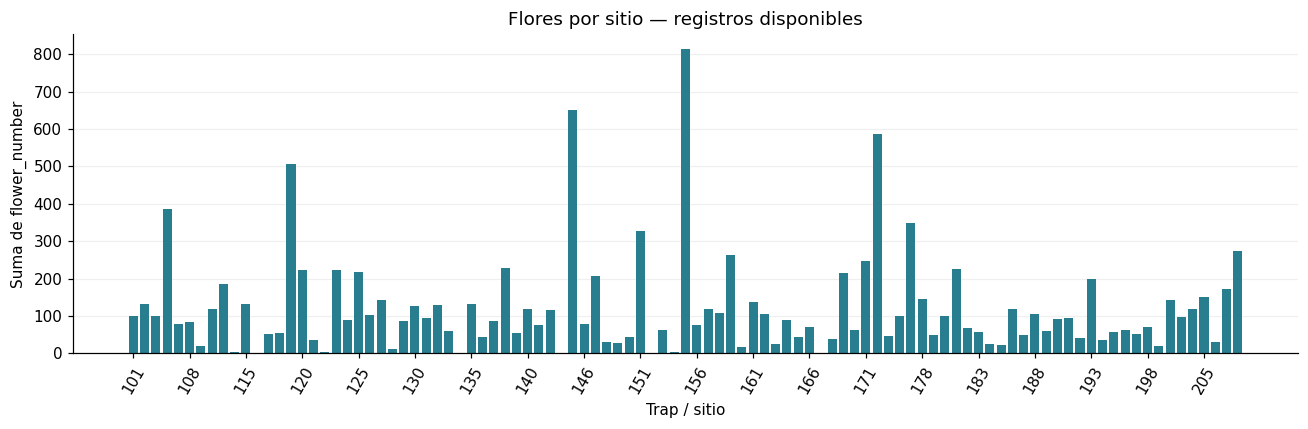

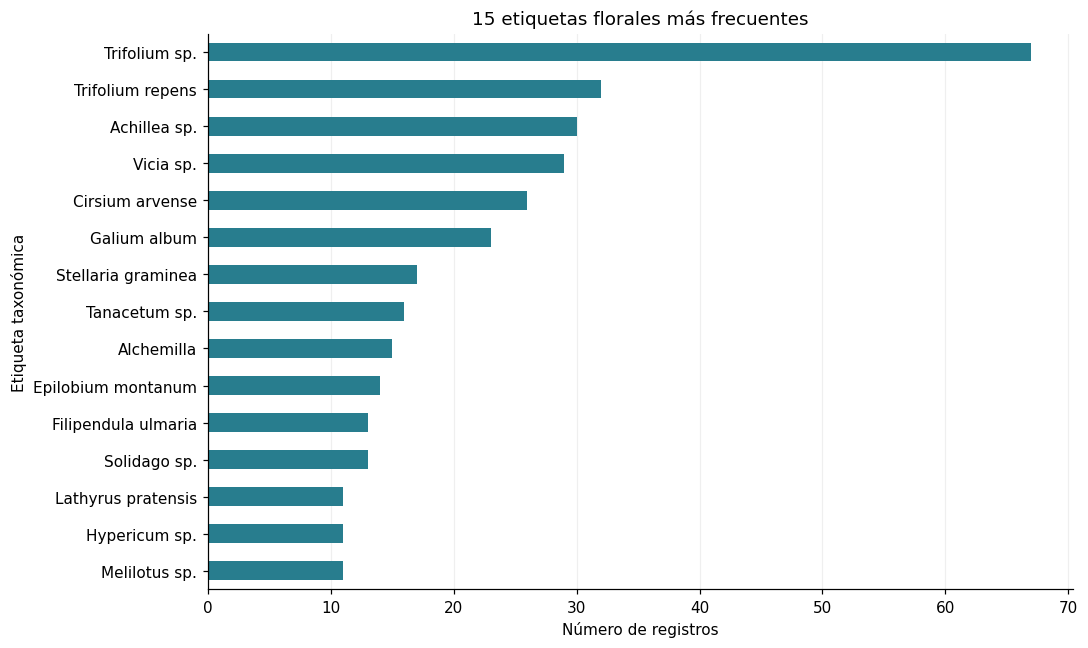

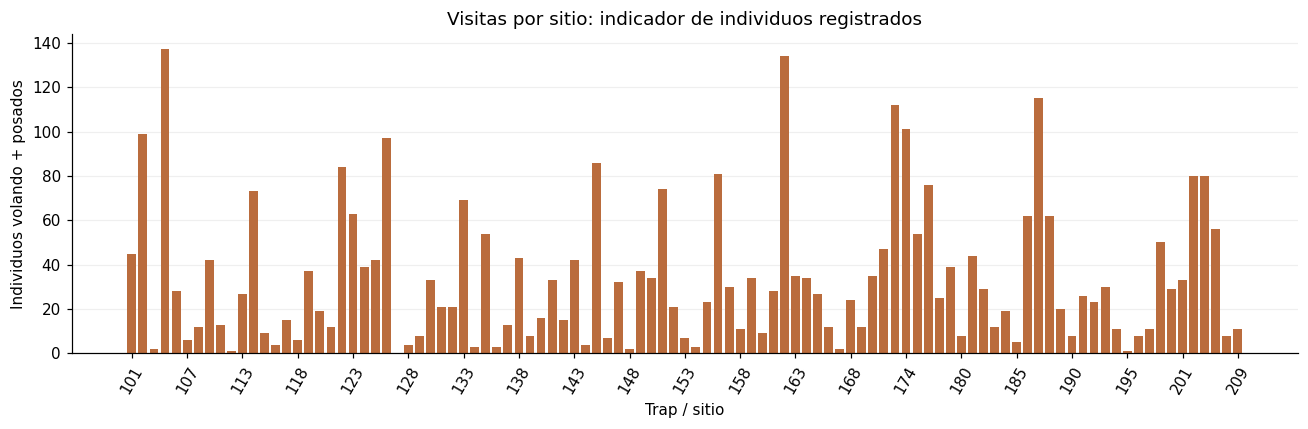

In [11]:
def site_bars(df, value, title, ylabel, color):
    if not available(df, ["trap_number", value], title):
        return
    totals = df.groupby("trap_number")[value].sum(min_count=1).dropna()
    if totals.empty:
        print(title + ": sin datos")
        return
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(totals.index.astype(str), totals.values, color=color)
    ax.set(title=title, xlabel="Trap / sitio", ylabel=ylabel)
    ax.set_xticks(np.arange(0, len(totals), 5), totals.index.astype(str)[::5], rotation=60)
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()

site_bars(flora, "flower_number", "Flores por sitio — registros disponibles", "Suma de flower_number", "#287D8E")
if "plant_species_latin_name" in flora:
    top = flora.plant_species_latin_name.value_counts().head(15).sort_values()
    if not top.empty:
        fig, ax = plt.subplots(figsize=(10, 6))
        top.plot.barh(ax=ax, color="#287D8E")
        ax.set(title="15 etiquetas florales más frecuentes", xlabel="Número de registros", ylabel="Etiqueta taxonómica")
        ax.grid(axis="x", alpha=.2)
        ax.set_axisbelow(True)
        fig.tight_layout()
        plt.show()
site_bars(visitas, "individuals_total", "Visitas por sitio: indicador de individuos registrados",
          "Individuos volando + posados", "#BA6C3D")

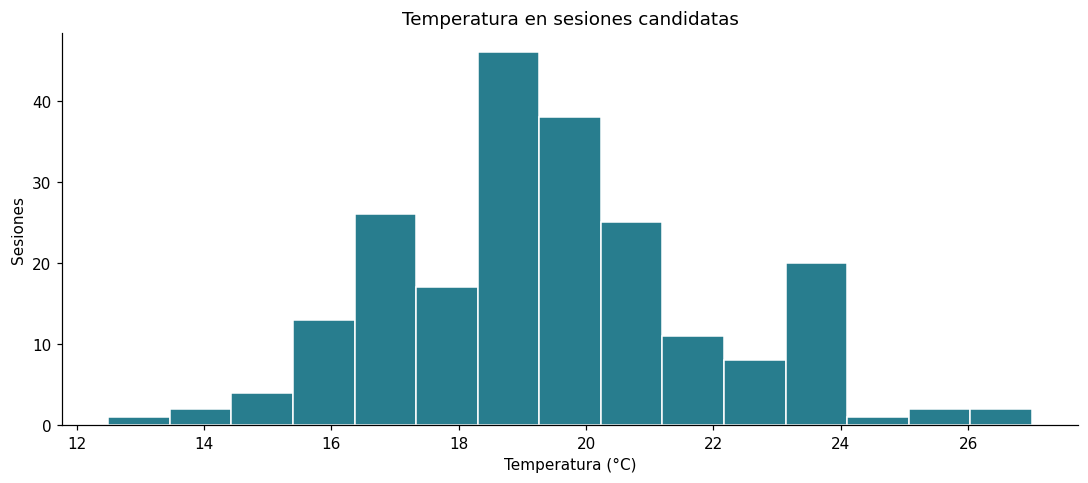

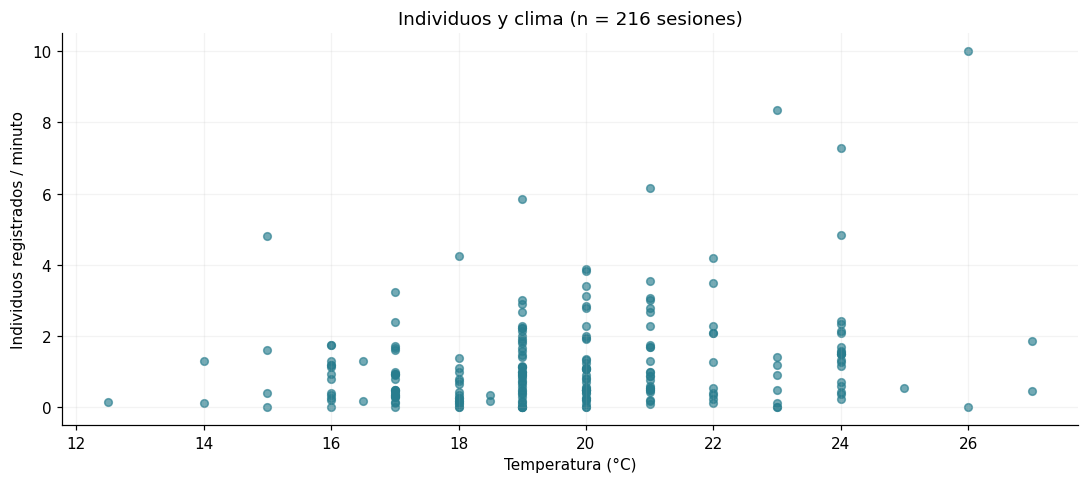

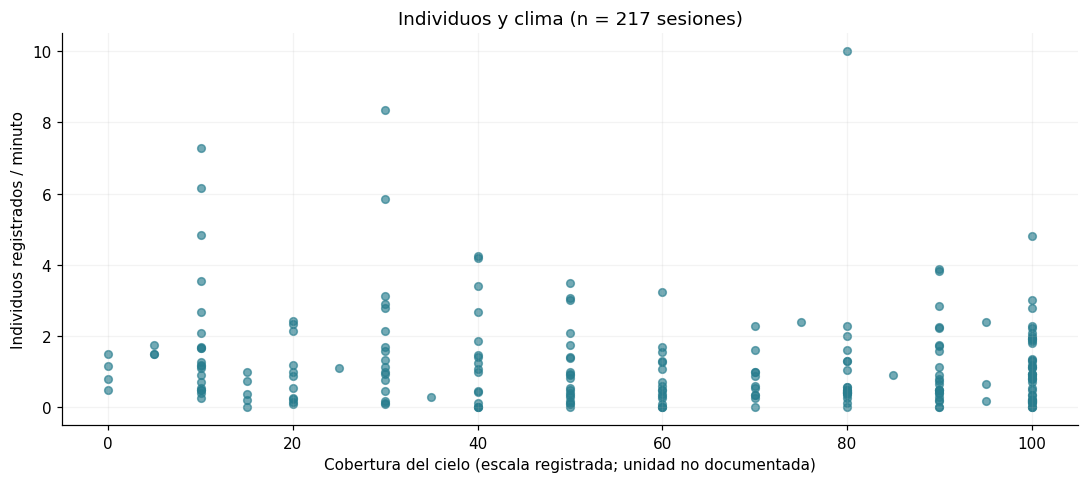

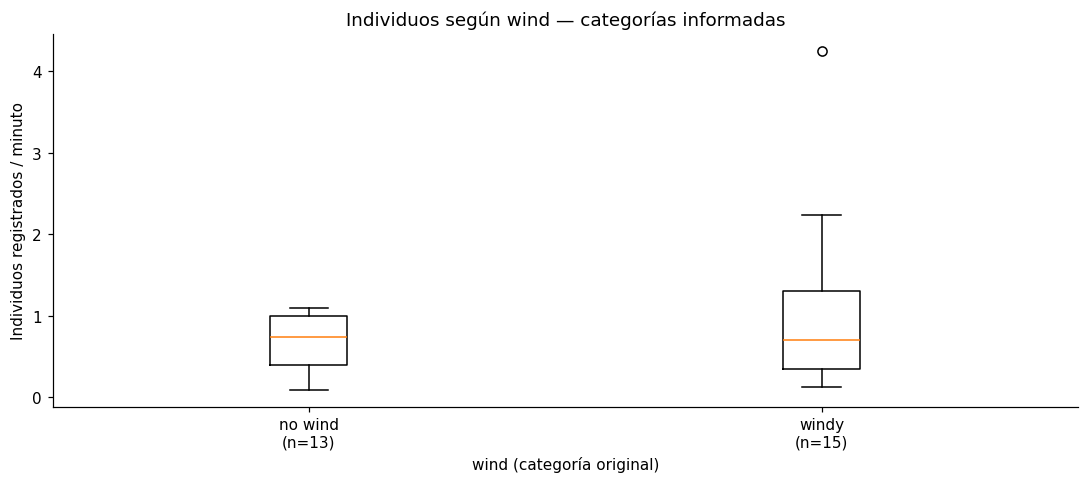

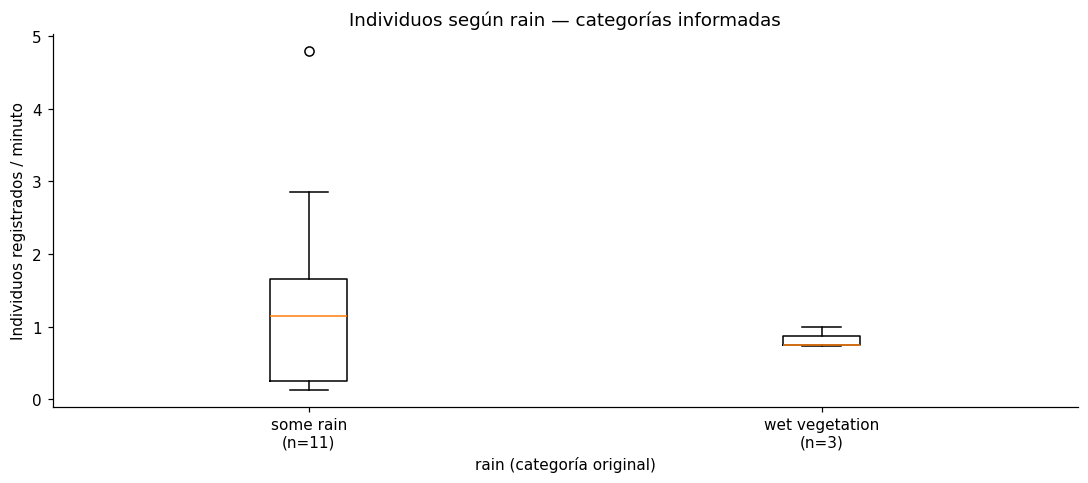

In [12]:
if not sessions.empty:
    if "temperature_C" in sessions and sessions.temperature_C.notna().any():
        fig, ax = plt.subplots()
        ax.hist(sessions.temperature_C.dropna(), bins="auto", color="#287D8E", edgecolor="white")
        ax.set(title="Temperatura en sesiones candidatas", xlabel="Temperatura (°C)", ylabel="Sesiones")
        fig.tight_layout()
        plt.show()
    for col, label in [("temperature_C", "Temperatura (°C)"),
                       ("sky_cover", "Cobertura del cielo (escala registrada; unidad no documentada)")]:
        if col in sessions:
            points = sessions[[col, "individuals_per_min"]].dropna()
            if not points.empty:
                fig, ax = plt.subplots()
                ax.scatter(points[col], points.individuals_per_min, alpha=.65, s=25, color="#287D8E")
                ax.set(title=f"Individuos y clima (n = {len(points)} sesiones)",
                       xlabel=label, ylabel="Individuos registrados / minuto")
                ax.grid(alpha=.15)
                fig.tight_layout()
                plt.show()
    for col in [x for x in ["wind", "rain"] if x in sessions]:
        groups = [(str(k), g.individuals_per_min.dropna()) for k, g in sessions.dropna(subset=[col]).groupby(col)]
        groups = [(k, s) for k, s in groups if not s.empty]
        if groups:
            fig, ax = plt.subplots()
            # Etiquetas por separado para compatibilidad entre versiones de matplotlib.
            ax.boxplot([s.to_numpy() for _, s in groups], showfliers=True)
            ax.set_xticks(range(1, len(groups) + 1), [f"{k}\n(n={len(s)})" for k, s in groups])
            ax.set(title=f"Individuos según {col} — categorías informadas",
                   xlabel=f"{col} (categoría original)", ylabel="Individuos registrados / minuto")
            fig.tight_layout()
            plt.show()
else:
    print("Sin sesiones candidatas utilizables para gráficas climáticas.")

## 11. Variables disponibles para Proyecto 2
La tabla cubre todas las columnas originales, indicadores derivados y variables faltantes. «Observada directamente» se refiere al valor registrado, no a la interpretación posterior. Los usos propuestos no constituyen calibración del simulador.

In [13]:
definitions = {
"trap_number": ("identificador", "Identificar nodos de muestreo", "No contiene coordenadas ni distancias"),
"inventory_date": ("fecha o día/mes", "Calendario", "Flora mayoritariamente sin año; no imputado"),
"plant_species_latin_name": ("etiqueta taxonómica", "Composición floral de nodos", "Incluye identificaciones por encima de especie"),
"flower_number": ("valor floral registrado; incluye fracciones", "Indicador provisional de oferta floral", "14 valores fraccionarios; definición por confirmar; no mide recursos"),
"transect_width_cm": ("cm", "Superficie muestreada", "No es una coordenada ni radio de vuelo"),
"transect_length_m": ("m", "Superficie muestreada", "El esfuerzo varía entre transectos"),
"comments": ("texto libre", "Control de calidad", "Revisar notas de no floración"),
"observer1": ("código", "Controlar diferencias de observador", "No identifica sesión por sí solo"),
"observer2": ("código", "Controlar esfuerzo", "Ausente no demuestra observador único"),
"observation_start": ("HH:MM; zona no documentada", "Duración y franja horaria", "Sin ID de sesión"),
"observation_end": ("HH:MM; zona no documentada", "Duración", "Hay ausencias y valor no interpretable"),
"temperature_C": ("°C", "Actividad según temperatura", "No hay serie continua ni causalidad demostrada"),
"sky_cover": ("escala numérica; unidad no documentada", "Actividad según cielo", "No asumir porcentaje sin protocolo"),
"wind": ("categoría textual", "Escenarios de viento", "Sin velocidad; muchos ausentes"),
"rain": ("categoría textual", "Escenarios de humedad/lluvia", "Sin mm; wet vegetation no es intensidad de lluvia"),
"additional_comments": ("texto libre", "Contexto y calidad", "Muy incompleto; requiere lectura"),
"pollinator_species_latin": ("etiqueta taxonómica", "Grupos de agentes candidatos", "Grupos amplios, ausencias y variantes"),
"sex": ("categoría textual", "Describir submuestra", "Cobertura insuficiente para generalizar"),
"individuals_flying": ("conteo de individuos registrados", "Actividad de vuelo", "No implica visita floral ni individuo único"),
"individuals_sitting": ("conteo de individuos registrados", "Actividad posada", "No implica polinización efectiva"),
"plant_species_latin": ("etiqueta taxonómica", "Asociaciones planta–polinizador", "Posarse no confirma transferencia de polen")}
rows = []
for source, df in raw.items():
    for variable in df:
        unit, use, note = definitions.get(variable, ("no documentada", "Revisar", "Columna no prevista"))
        rows.append([variable, FILES[source], "sí (valor registrado)", unit, use, note])
for variable, source, unit, use, note in [
    ("date_complete / month / day", "ambos: inventory_date", "fecha / mes / día", "Orden temporal", "No se inventa año ausente"),
    ("transect_area_m2", "flora: ancho × largo", "m²", "Normalizar superficie", "No sumar área repetida por taxón"),
    ("flowers_per_m2_record", "flora: flores / área", "flores registradas/m²", "Oferta floral por registro", "Solo área positiva; revisar duplicados"),
    ("individuals_total", "visitas: flying + sitting", "individuos registrados", "Actividad", "No equivale a visitas ni individuos únicos"),
    ("duration_min / individuals_per_min", "visitas: horarios y sesiones candidatas", "min / individuos registrados por min", "Esfuerzo y actividad", "Agrupación por validar; exclusiones reportadas"),
    ("riqueza y asociaciones taxonómicas", "ambos: etiquetas y agrupaciones", "conteos / coocurrencias", "Composición y enlaces candidatos", "Requiere armonización y compatibilidad temporal")]:
    rows.append([variable, source, "no; derivada", unit, use, note])
for variable, use in [("coordenadas, distancias y conectividad", "Geometría y movimiento espacial"),
                      ("polen y néctar", "Recursos y recompensas"),
                      ("agotamiento y reposición", "Dinámica de recursos"),
                      ("competencia y conducta de movimiento", "Interacción y decisiones"),
                      ("polinización efectiva", "Resultado ecológico")]:
    rows.append([variable, "no disponible en estos archivos", "no", "por definir y justificar", use,
                 "Requiere estimación o modelado; no asignar valores desde estos conteos"])
variables_disponibles_proyecto2 = pd.DataFrame(rows, columns=["variable", "dataset/fuente", "observada directamente",
    "unidad o escala", "posible uso en el simulador", "observaciones/limitaciones"])
display(variables_disponibles_proyecto2)

,variable,dataset/fuente,observada directamente,unidad o escala,posible uso en el simulador,observaciones/limitaciones
0,trap_number,floral_density_data_dryad_version.txt,sí (valor registrado),identificador,Identificar nodos de muestreo,No contiene coordenadas ni distancias
1,inventory_date,floral_density_data_dryad_version.txt,sí (valor registrado),fecha o día/mes,Calendario,Flora mayoritariamente sin año; no imputado
2,plant_species_latin_name,floral_density_data_dryad_version.txt,sí (valor registrado),etiqueta taxonómica,Composición floral de nodos,Incluye identificaciones por encima de especie
3,flower_number,floral_density_data_dryad_version.txt,sí (valor registrado),valor floral registrado; incluye fracciones,Indicador provisional de oferta floral,14 valores fraccionarios; definición por confirmar; no mide recursos
4,transect_width_cm,floral_density_data_dryad_version.txt,sí (valor registrado),cm,Superficie muestreada,No es una coordenada ni radio de vuelo
5,transect_length_m,floral_density_data_dryad_version.txt,sí (valor registrado),m,Superficie muestreada,El esfuerzo varía entre transectos
6,comments,floral_density_data_dryad_version.txt,sí (valor registrado),texto libre,Control de calidad,Revisar notas de no floración
7,trap_number,floral_visitation_data_dryad_version.txt,sí (valor registrado),identificador,Identificar nodos de muestreo,No contiene coordenadas ni distancias
8,inventory_date,floral_visitation_data_dryad_version.txt,sí (valor registrado),fecha o día/mes,Calendario,Flora mayoritariamente sin año; no imputado
9,observer1,floral_visitation_data_dryad_version.txt,sí (valor registrado),código,Controlar diferencias de observador,No identifica sesión por sí solo


## 12. Observaciones, derivaciones y supuestos pendientes
**Datos observados directamente:** códigos de trap, fechas tal como se registraron, taxones, flores, dimensiones de transecto, individuos volando/posados, plantas asociadas, horarios, observadores, clima y comentarios presentes. Un valor registrado puede contener error o ambigüedad.

**Variables derivables:** área, flores por m² por registro y eventualmente por transecto validado, conteos agregados, riqueza de etiquetas, composición por trap, duración válida, actividad por minuto en sesiones candidatas, asociaciones planta–polinizador y cobertura temporal. Deben conservarse denominadores, ausencias y esfuerzo. Un enlace por trap no garantiza coincidencia temporal: casi todas las fechas florales carecen de año. Unir directamente las filas de ambas tablas podría multiplicar registros.

**Variables por estimar o modelar:** cantidad y calidad de polen/néctar, extracción, agotamiento, reposición, competencia, movimiento y radios de vuelo, preferencias, demografía y polinización efectiva. Faltan también coordenadas, distancias y clima continuo. Requieren supuestos explícitos, otras fuentes en una fase posterior y análisis de sensibilidad; aquí no se asignan datos ni unidades ficticias.

## 13. Conclusiones para el modelo espacial y temporal
La síntesis siguiente se calcula sobre las tablas cargadas. Los totales conservan todas las filas originales; el efecto de excluir duplicados se presentó como sensibilidad.

In [14]:
for label, df in raw.items():
    print(f"• {label}: {len(df):,} registros, {len(df.columns)} columnas y {int(df.duplicated().sum())} duplicados exactos adicionales.")
for label, df in data.items():
    if "trap_number" in df:
        print(f"• {label}: {df.trap_number.nunique()} traps únicos.")
if "flower_number" in flora:
    print(f"• Suma de flower_number: {flora.flower_number.sum(min_count=1):,.9f}; {flora.flower_number.isna().sum()} valores ausentes (incluye fracciones; no es conteo entero confirmado).")
if "individuals_total" in visitas:
    print(f"• Individuos registrados: {visitas.individuals_total.sum(min_count=1):,.0f}; no equivalen a visitas efectivas.")
if "date_status" in flora:
    print(f"• Fechas florales sin año: {flora.date_status.eq('parcial sin año').sum()} de {len(flora)} registros.")
if "date_complete" in visitas and visitas.date_complete.notna().any():
    print(f"• Visitas: {visitas.date_complete.min().date()} a {visitas.date_complete.max().date()}; {visitas.date_complete.isna().sum()} fechas ausentes/no interpretables.")
if "temperature_C" in visitas:
    print(f"• Temperatura: {visitas.temperature_C.min():g}–{visitas.temperature_C.max():g} °C.")
for col in ["wind", "rain"]:
    if col in visitas:
        print(f"• {col}: {visitas[col].isna().sum()} registros ausentes ({visitas[col].isna().mean():.1%}).")

• flora: 593 registros, 7 columnas y 4 duplicados exactos adicionales.
• visitas: 1,297 registros, 16 columnas y 6 duplicados exactos adicionales.
• flora: 100 traps únicos.
• visitas: 101 traps únicos.
• Suma de flower_number: 12,063.016666666; 1 valores ausentes (incluye fracciones; no es conteo entero confirmado).
• Individuos registrados: 3,431; no equivalen a visitas efectivas.
• Fechas florales sin año: 577 de 593 registros.
• Visitas: 2017-07-18 a 2017-08-10; 1 fechas ausentes/no interpretables.
• Temperatura: 12.5–27 °C.
• wind: 1096 registros ausentes (84.5%).
• rain: 1208 registros ausentes (93.1%).


Los traps permiten definir **nodos de muestreo** con composición floral y actividad registrada. Las dimensiones permiten comparar oferta por superficie tras validar la unidad de muestreo. Para representar un espacio geográfico hacen falta coordenadas y distancias: el identificador no es una posición.

Las fechas completas y horarios permiten describir ventanas temporales y explorar actividad frente al clima en esta muestra. No permiten inferir ciclos anuales ni dinámica continua de recursos; las fechas florales parciales y los horarios incompletos limitan la sincronización y las tasas.

Antes de calibrar se deben revisar duplicados, taxonomía, comentarios de no floración, compatibilidad de sesiones y ausencias. La cobertura climática es desigual y no demuestra causalidad. Oslo aporta una base para nodos, composición y actividad; **polen, néctar, agotamiento, competencia y polinización efectiva permanecen sin medir** en estos archivos.